# 08 — Image Quality and Diversity Evaluation

## Project
**Synthetic Ocular Image Generation using Diffusion Models for Biometric Augmentation**

## Dataset
**CASIA-Iris-Thousand**

## Objective

This notebook evaluates the quality, realism, and diversity of the synthetic ocular images generated by the trained diffusion models.

The evaluation focuses on two major aspects:

1. **Image Quality**
2. **Image Diversity**

The goal is to determine whether the generated ocular images are visually and statistically consistent with the real CASIA-Iris-Thousand images while also providing meaningful variation rather than producing near-duplicate samples.

---

## 1. Image Quality Evaluation

The generated images will be compared with real ocular images using quantitative image-generation metrics.

The evaluation will include, where applicable:

- **FID (Fréchet Inception Distance)**
- **KID (Kernel Inception Distance)**
- **LPIPS (Learned Perceptual Image Patch Similarity)**
- **SSIM (Structural Similarity Index)**
- **PSNR (Peak Signal-to-Noise Ratio)**

These metrics will be interpreted according to whether a valid comparison is possible.

For example, SSIM and PSNR are appropriate for paired images with a meaningful correspondence, whereas distribution-level metrics such as FID and KID are intended to compare sets of real and generated images.

---

## 2. Real vs Synthetic Distribution Analysis

The statistical properties of the real and generated image sets will also be examined.

The analysis will include:

- Mean intensity
- Standard deviation
- Intensity distribution
- Pixel-value histogram
- Basic distribution differences

This provides an additional quantitative view of how closely the synthetic images resemble the real ocular-image dataset at the image-distribution level.

---

## 3. Image Diversity Evaluation

A major objective of synthetic biometric generation is to produce diverse samples rather than repeated or nearly identical images.

Generated samples will therefore be evaluated using:

- Pairwise feature distance
- LPIPS-based diversity
- Feature-space variance
- Intra-identity variation
- Inter-identity variation

For identity-conditioned generation, intra-identity and inter-identity variation will be examined separately to determine whether the model produces:

- meaningful variation within the same identity
- distinguishable variation between different identities

---

## 4. Feature-Space Analysis

Deep image features will be extracted from the real and generated images using a pretrained feature extractor.

These features will be used to measure:

- Similarity between real and synthetic images
- Diversity among generated samples
- Intra-identity feature variation
- Inter-identity feature variation

The feature-space analysis will complement the pixel-level measurements because pixel similarity alone does not adequately describe perceptual or structural similarity.

---

## 5. Important Evaluation Considerations

The evaluation will distinguish between:

- **paired metrics**, which require meaningful image correspondence
- **distribution-level metrics**, which compare real and synthetic image sets
- **feature-space metrics**, which measure similarity and diversity in learned representations

Independent synthetic images will not be treated as pixel-level reconstructions of arbitrary real images. Therefore, PSNR/SSIM will only be reported when a valid paired comparison exists.

The limitations of generic pretrained feature extractors for ocular biometric evaluation will also be documented.

---

## 6. Outputs

This notebook will produce:

- Image-quality metric results
- Real-vs-synthetic distribution statistics
- Diversity measurements
- Feature-space similarity analysis
- Intra-identity and inter-identity diversity measurements
- CSV files containing quantitative results
- JSON summary of the experiment

These results will later be used in:

**Notebook 9 — Dataset Augmentation**

and

**Notebook 10 — Recognition with Augmented Data**

to determine whether the synthetic images provide useful augmentation for ocular biometric recognition.

In [ ]:
# ============================================================
# Cell 2 — Imports and Experiment Configuration
# ============================================================

import os
import json
import math
import random
import numpy as np
import pandas as pd
from pathlib import Path

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader

from PIL import Image

import torchvision
from torchvision import transforms

print("PyTorch version:", torch.__version__)
print("Torchvision version:", torchvision.__version__)

# ------------------------------------------------------------
# Device
# ------------------------------------------------------------

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Device:", device)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print(
        "GPU memory:",
        round(torch.cuda.get_device_properties(0).total_memory / 1024**3, 2),
        "GB"
    )

# ------------------------------------------------------------
# Reproducibility
# ------------------------------------------------------------

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

# ------------------------------------------------------------
# Project paths
# ------------------------------------------------------------

PROJECT_ROOT = Path(
    r"C:\Users\kavya\Downloads\Ocular_Project"
)

DATASET_ROOT = (
    PROJECT_ROOT
    / "datasets"
    / "CASIA-Iris-Thousand"
    / "CASIA-Iris-Thousand"
)

CSV_PATH = (
    PROJECT_ROOT
    / "datasets"
    / "iris_thousands.csv"
)

# Identity-conditioned generation results
GENERATION_DIR = (
    PROJECT_ROOT
    / "results"
    / "identity_conditioned_generation"
)

# Output directory for Notebook 8
OUTPUT_DIR = (
    PROJECT_ROOT
    / "results"
    / "notebook_08_quality_diversity"
)

OUTPUT_DIR.mkdir(
    parents=True,
    exist_ok=True
)

# ------------------------------------------------------------
# Evaluation configuration
# ------------------------------------------------------------

IMAGE_SIZE = 224
NUM_CHANNELS = 1

# Number of generated samples expected from Notebook 7
EXPECTED_GENERATED_SAMPLES = 64

# Random seed used for reproducible sampling
EVAL_SEED = 42

# ------------------------------------------------------------
# Display configuration
# ------------------------------------------------------------

print("\nProject root:")
print(PROJECT_ROOT)

print("\nDataset root:")
print(DATASET_ROOT)

print("\nCSV:")
print(CSV_PATH)

print("\nGenerated images:")
print(GENERATION_DIR)

print("\nNotebook 8 output:")
print(OUTPUT_DIR)

# ------------------------------------------------------------
# Basic path checks
# ------------------------------------------------------------

required_paths = {
    "Project root": PROJECT_ROOT,
    "Dataset root": DATASET_ROOT,
    "CSV file": CSV_PATH,
    "Generation directory": GENERATION_DIR,
}

print("\nPath verification:")

for name, path in required_paths.items():
    print(
        f"{name:25s}:",
        "✓ EXISTS" if path.exists() else "✗ MISSING",
        "->",
        path
    )

print("\nConfiguration loaded successfully.")

PyTorch version: 2.11.0+cu128
Torchvision version: 0.26.0+cu128
Device: cuda
GPU: NVIDIA GeForce RTX 4060 Laptop GPU
GPU memory: 8.0 GB

Project root:
C:\Users\kavya\Downloads\Ocular_Project

Dataset root:
C:\Users\kavya\Downloads\Ocular_Project\datasets\CASIA-Iris-Thousand\CASIA-Iris-Thousand

CSV:
C:\Users\kavya\Downloads\Ocular_Project\datasets\iris_thousands.csv

Generated images:
C:\Users\kavya\Downloads\Ocular_Project\results\identity_conditioned_generation

Notebook 8 output:
C:\Users\kavya\Downloads\Ocular_Project\results\notebook_08_quality_diversity

Path verification:
Project root             : ✓ EXISTS -> C:\Users\kavya\Downloads\Ocular_Project
Dataset root             : ✓ EXISTS -> C:\Users\kavya\Downloads\Ocular_Project\datasets\CASIA-Iris-Thousand\CASIA-Iris-Thousand
CSV file                 : ✓ EXISTS -> C:\Users\kavya\Downloads\Ocular_Project\datasets\iris_thousands.csv
Generation directory     : ✓ EXISTS -> C:\Users\kavya\Downloads\Ocular_Project\results\identity_cond

In [ ]:
# ============================================================
# Cell 3 — Load and Inspect Real + Generated Image Sets
# ============================================================

from collections import Counter

# ------------------------------------------------------------
# Load dataset CSV
# ------------------------------------------------------------

df = pd.read_csv(CSV_PATH)

print("CSV shape:", df.shape)
print("CSV columns:", list(df.columns))

# ------------------------------------------------------------
# Reconstruct local image paths
# ------------------------------------------------------------

def resolve_local_path(image_path):
    image_path = str(image_path)

    marker = "CASIA-Iris-Thousand"

    if marker in image_path:
        relative_part = image_path.split(
            marker, 1
        )[1].lstrip("\\/")

        return DATASET_ROOT / relative_part

    return Path(image_path)


df["LocalPath"] = df["ImagePath"].apply(
    resolve_local_path
)

# ------------------------------------------------------------
# Verify real image paths
# ------------------------------------------------------------

existing_count = df["LocalPath"].apply(
    Path.exists
).sum()

print("\nLocal path verification:")
print("Existing images:", existing_count)
print("Missing images:", len(df) - existing_count)

# ------------------------------------------------------------
# Real dataset identity statistics
# ------------------------------------------------------------

unique_identities = df["Label"].nunique()

print("\nReal dataset statistics:")
print("Total images:", len(df))
print("Unique identities:", unique_identities)

images_per_identity = df.groupby("Label").size()

print(
    "Images per identity:",
    images_per_identity.min(),
    "to",
    images_per_identity.max()
)

# ------------------------------------------------------------
# Inspect generated directory
# ------------------------------------------------------------

generated_files = sorted([
    p for p in GENERATION_DIR.iterdir()
    if p.suffix.lower() in [
        ".png",
        ".jpg",
        ".jpeg",
        ".pt",
        ".pth",
        ".npy"
    ]
])

print("\nGenerated files found:", len(generated_files))

# Only actual image files
generated_image_files = [
    p for p in generated_files
    if p.suffix.lower() in [
        ".png",
        ".jpg",
        ".jpeg"
    ]
]

print(
    "Generated image files:",
    len(generated_image_files)
)

# ------------------------------------------------------------
# Inspect first generated image
# ------------------------------------------------------------

if len(generated_image_files) > 0:

    sample_path = generated_image_files[0]

    sample_image = Image.open(sample_path)

    print("\nFirst generated image:")
    print("Filename:", sample_path.name)
    print("Size:", sample_image.size)
    print("Mode:", sample_image.mode)

    sample_array = np.asarray(sample_image)

    print("Array shape:", sample_array.shape)
    print("Data type:", sample_array.dtype)
    print("Min:", sample_array.min())
    print("Max:", sample_array.max())
    print("Mean:", sample_array.mean())
    print("Std:", sample_array.std())

# ------------------------------------------------------------
# Inspect first real image
# ------------------------------------------------------------

first_real_path = df.iloc[0]["LocalPath"]

real_image = Image.open(first_real_path)

print("\nFirst real image:")
print("Filename:", first_real_path.name)
print("Size:", real_image.size)
print("Mode:", real_image.mode)

real_array = np.asarray(real_image)

print("Array shape:", real_array.shape)
print("Data type:", real_array.dtype)
print("Min:", real_array.min())
print("Max:", real_array.max())
print("Mean:", real_array.mean())
print("Std:", real_array.std())

# ------------------------------------------------------------
# Expected generated sample check
# ------------------------------------------------------------

print("\nGenerated sample count check:")

if len(generated_image_files) == EXPECTED_GENERATED_SAMPLES:
    print(
        f"✓ Expected {EXPECTED_GENERATED_SAMPLES} "
        "generated images found."
    )
else:
    print(
        f"⚠ Expected {EXPECTED_GENERATED_SAMPLES}, "
        f"but found {len(generated_image_files)} "
        "generated images."
    )

print("\nCell 3 inspection complete.")

In [ ]:
# ============================================================
# Cell 4 — Locate Generated Images Recursively
# ============================================================

print("Searching recursively inside:")
print(GENERATION_DIR)

# ------------------------------------------------------------
# Find every file inside the generation directory
# ------------------------------------------------------------

all_files = []

for root, dirs, files in os.walk(GENERATION_DIR):
    for file in files:
        all_files.append(Path(root) / file)

print("\nTotal files found recursively:", len(all_files))

# ------------------------------------------------------------
# Show all files
# ------------------------------------------------------------

if len(all_files) > 0:

    print("\nFiles found:")

    for path in all_files:
        relative_path = path.relative_to(GENERATION_DIR)
        print(" -", relative_path)

else:
    print("\n⚠ No files found anywhere inside the generation directory.")

# ------------------------------------------------------------
# Find image files recursively
# ------------------------------------------------------------

image_extensions = {
    ".png",
    ".jpg",
    ".jpeg",
    ".bmp",
    ".tif",
    ".tiff"
}

recursive_image_files = [
    path
    for path in all_files
    if path.suffix.lower() in image_extensions
]

print("\n----------------------------------------")
print("Generated image search")
print("----------------------------------------")

print(
    "Image files found recursively:",
    len(recursive_image_files)
)

# ------------------------------------------------------------
# Show image locations
# ------------------------------------------------------------

if len(recursive_image_files) > 0:

    print("\nGenerated image locations:")

    for path in recursive_image_files[:100]:
        print(
            " -",
            path.relative_to(GENERATION_DIR)
        )

    if len(recursive_image_files) > 100:
        print(
            f"\n... and "
            f"{len(recursive_image_files) - 100} more"
        )

# ------------------------------------------------------------
# Count file types
# ------------------------------------------------------------

from collections import Counter

extension_counts = Counter(
    path.suffix.lower()
    for path in all_files
)

print("\n----------------------------------------")
print("File type summary")
print("----------------------------------------")

for extension, count in sorted(
    extension_counts.items()
):
    print(
        f"{extension or '[no extension]':10s}: {count}"
    )

print("\nCell 4 complete.")

Searching recursively inside:
C:\Users\kavya\Downloads\Ocular_Project\results\identity_conditioned_generation

Total files found recursively: 133

Files found:
 - feature_space_identity_evaluation.csv
 - generation_records.csv
 - generation_summary.json
 - identity_consistency_metrics.csv
 - identity_generation_summary.csv
 - identity_0000\sample_01.png
 - identity_0000\sample_01.pt
 - identity_0000\sample_02.png
 - identity_0000\sample_02.pt
 - identity_0000\sample_03.png
 - identity_0000\sample_03.pt
 - identity_0000\sample_04.png
 - identity_0000\sample_04.pt
 - identity_0079\sample_01.png
 - identity_0079\sample_01.pt
 - identity_0079\sample_02.png
 - identity_0079\sample_02.pt
 - identity_0079\sample_03.png
 - identity_0079\sample_03.pt
 - identity_0079\sample_04.png
 - identity_0079\sample_04.pt
 - identity_0159\sample_01.png
 - identity_0159\sample_01.pt
 - identity_0159\sample_02.png
 - identity_0159\sample_02.pt
 - identity_0159\sample_03.png
 - identity_0159\sample_03.pt
 - i

In [ ]:
# ============================================================
# Cell 5 — Build Evaluation Metadata and Load Generated Images
# ============================================================

# ------------------------------------------------------------
# Collect generated PNG files
# ------------------------------------------------------------

generated_image_files = sorted(
    recursive_image_files,
    key=lambda p: (
        p.parent.name,
        p.name
    )
)

print("Generated PNG files:", len(generated_image_files))

# ------------------------------------------------------------
# Build generated-image metadata
# ------------------------------------------------------------

generated_records = []

for path in generated_image_files:

    # Example folder:
    # identity_0000
    identity_folder = path.parent.name

    # Extract numeric identity
    identity_id = int(
        identity_folder.replace("identity_", "")
    )

    # Extract sample number
    sample_name = path.stem
    sample_id = int(
        sample_name.replace("sample_", "")
    )

    generated_records.append({
        "Identity": identity_id,
        "IdentityFolder": identity_folder,
        "Sample": sample_id,
        "Filename": path.name,
        "Path": str(path)
    })

generated_df = pd.DataFrame(
    generated_records
)

# ------------------------------------------------------------
# Sort metadata
# ------------------------------------------------------------

generated_df = generated_df.sort_values(
    ["Identity", "Sample"]
).reset_index(drop=True)

print("\nGenerated metadata:")
print(generated_df.head(10))

# ------------------------------------------------------------
# Basic identity statistics
# ------------------------------------------------------------

print("\nGenerated identity statistics:")

print(
    "Unique generated identities:",
    generated_df["Identity"].nunique()
)

print(
    "Samples per identity:"
)

print(
    generated_df.groupby("Identity")
    .size()
    .value_counts()
    .sort_index()
)

# ------------------------------------------------------------
# Load generated images
# ------------------------------------------------------------

generated_images = []
generated_image_stats = []

for _, row in generated_df.iterrows():

    image_path = Path(row["Path"])

    image = Image.open(
        image_path
    ).convert("L")

    image_array = np.asarray(
        image,
        dtype=np.uint8
    )

    generated_images.append(
        image_array
    )

    generated_image_stats.append({
        "Identity": row["Identity"],
        "Sample": row["Sample"],
        "Height": image_array.shape[0],
        "Width": image_array.shape[1],
        "Min": float(image_array.min()),
        "Max": float(image_array.max()),
        "Mean": float(image_array.mean()),
        "Std": float(image_array.std())
    })

generated_images = np.stack(
    generated_images
)

generated_stats_df = pd.DataFrame(
    generated_image_stats
)

# ------------------------------------------------------------
# Generated image verification
# ------------------------------------------------------------

print("\nGenerated image tensor:")
print("Shape:", generated_images.shape)
print("Dtype:", generated_images.dtype)

print(
    "Global minimum:",
    generated_images.min()
)

print(
    "Global maximum:",
    generated_images.max()
)

print(
    "Global mean:",
    generated_images.mean()
)

print(
    "Global std:",
    generated_images.std()
)

# ------------------------------------------------------------
# Image dimensions
# ------------------------------------------------------------

print("\nGenerated image dimensions:")

print(
    generated_stats_df[
        ["Height", "Width"]
    ].drop_duplicates()
)

# ------------------------------------------------------------
# Generated image statistics
# ------------------------------------------------------------

print("\nGenerated image statistics:")
print(
    generated_stats_df[
        ["Min", "Max", "Mean", "Std"]
    ].describe()
)

# ------------------------------------------------------------
# Prepare real-image metadata
# ------------------------------------------------------------

real_df = df[
    ["Label", "LocalPath"]
].copy()

real_df = real_df.rename(
    columns={
        "Label": "Identity",
        "LocalPath": "Path"
    }
)

print("\nReal image metadata:")
print(real_df.head())

print(
    "\nReal images available for evaluation:",
    len(real_df)
)

print(
    "Real identities available:",
    real_df["Identity"].nunique()
)

# ------------------------------------------------------------
# Save generated metadata
# ------------------------------------------------------------

generated_df.to_csv(
    OUTPUT_DIR / "generated_image_metadata.csv",
    index=False
)

generated_stats_df.to_csv(
    OUTPUT_DIR / "generated_image_statistics.csv",
    index=False
)

print(
    "\nSaved:",
    OUTPUT_DIR / "generated_image_metadata.csv"
)

print(
    "Saved:",
    OUTPUT_DIR / "generated_image_statistics.csv"
)

print("\nCell 5 complete.")

Generated PNG files: 64

Generated metadata:
   Identity IdentityFolder  Sample       Filename  \
0         0  identity_0000       1  sample_01.png   
1         0  identity_0000       2  sample_02.png   
2         0  identity_0000       3  sample_03.png   
3         0  identity_0000       4  sample_04.png   
4        79  identity_0079       1  sample_01.png   
5        79  identity_0079       2  sample_02.png   
6        79  identity_0079       3  sample_03.png   
7        79  identity_0079       4  sample_04.png   
8       159  identity_0159       1  sample_01.png   
9       159  identity_0159       2  sample_02.png   

                                                Path  
0  C:\Users\kavya\Downloads\Ocular_Project\result...  
1  C:\Users\kavya\Downloads\Ocular_Project\result...  
2  C:\Users\kavya\Downloads\Ocular_Project\result...  
3  C:\Users\kavya\Downloads\Ocular_Project\result...  
4  C:\Users\kavya\Downloads\Ocular_Project\result...  
5  C:\Users\kavya\Downloads\Ocular_Projec

In [ ]:
# ============================================================
# Cell 6B — Memory-Efficient Distribution Statistics
# ============================================================

# ------------------------------------------------------------
# Histogram percentile function
# ------------------------------------------------------------

def histogram_percentiles(histogram, percentiles):
    """
    Calculate percentiles directly from a discrete histogram
    without expanding all pixel values into memory.
    """

    histogram = np.asarray(
        histogram,
        dtype=np.int64
    )

    cumulative = np.cumsum(histogram)
    total = cumulative[-1]

    results = []

    for percentile in percentiles:

        target = (
            percentile / 100.0
        ) * (total - 1)

        index = np.searchsorted(
            cumulative,
            target,
            side="left"
        )

        index = min(
            index,
            len(histogram) - 1
        )

        results.append(
            float(index)
        )

    return np.array(results)


# ------------------------------------------------------------
# Calculate percentiles safely
# ------------------------------------------------------------

percentile_values = [
    1,
    5,
    25,
    50,
    75,
    95,
    99
]

real_percentiles = histogram_percentiles(
    real_histogram,
    percentile_values
)

generated_percentiles = histogram_percentiles(
    generated_histogram,
    percentile_values
)

# ------------------------------------------------------------
# Recalculate distribution statistics
# ------------------------------------------------------------

real_mean = (
    real_sum /
    real_pixel_count
)

real_variance = (
    real_sum_sq /
    real_pixel_count
    - real_mean ** 2
)

real_std = np.sqrt(
    max(real_variance, 0)
)

generated_flat = generated_images.ravel()

generated_pixel_count = (
    generated_flat.size
)

generated_mean = float(
    generated_flat.mean()
)

generated_std = float(
    generated_flat.std()
)

generated_min = int(
    generated_flat.min()
)

generated_max = int(
    generated_flat.max()
)

# ------------------------------------------------------------
# Normalize histograms
# ------------------------------------------------------------

real_hist_norm = (
    real_histogram /
    real_histogram.sum()
)

generated_hist_norm = (
    generated_histogram /
    generated_histogram.sum()
)

# ------------------------------------------------------------
# Histogram comparison
# ------------------------------------------------------------

histogram_intersection = np.minimum(
    real_hist_norm,
    generated_hist_norm
).sum()

histogram_l1 = np.abs(
    real_hist_norm -
    generated_hist_norm
).sum()

# ------------------------------------------------------------
# Print real statistics
# ------------------------------------------------------------

print("\n" + "=" * 60)
print("REAL IMAGE INTENSITY STATISTICS")
print("=" * 60)

print(
    "Images:",
    len(real_df)
)

print(
    "Total pixels:",
    real_pixel_count
)

print(
    "Minimum:",
    real_min
)

print(
    "Maximum:",
    real_max
)

print(
    "Mean:",
    round(real_mean, 6)
)

print(
    "Std:",
    round(real_std, 6)
)

print("\nPercentiles:")

for percentile, value in zip(
    percentile_values,
    real_percentiles
):

    print(
        f"P{percentile:02d}:",
        round(value, 4)
    )

# ------------------------------------------------------------
# Print generated statistics
# ------------------------------------------------------------

print("\n" + "=" * 60)
print("GENERATED IMAGE INTENSITY STATISTICS")
print("=" * 60)

print(
    "Images:",
    len(generated_images)
)

print(
    "Total pixels:",
    generated_pixel_count
)

print(
    "Minimum:",
    generated_min
)

print(
    "Maximum:",
    generated_max
)

print(
    "Mean:",
    round(generated_mean, 6)
)

print(
    "Std:",
    round(generated_std, 6)
)

print("\nPercentiles:")

for percentile, value in zip(
    percentile_values,
    generated_percentiles
):

    print(
        f"P{percentile:02d}:",
        round(value, 4)
    )

# ------------------------------------------------------------
# Distribution comparison
# ------------------------------------------------------------

print("\n" + "=" * 60)
print("REAL vs GENERATED DISTRIBUTION")
print("=" * 60)

print(
    "Histogram intersection:",
    round(
        float(histogram_intersection),
        6
    )
)

print(
    "Histogram L1 distance:",
    round(
        float(histogram_l1),
        6
    )
)

# ------------------------------------------------------------
# Create summary table
# ------------------------------------------------------------

distribution_summary = pd.DataFrame([
    {
        "Dataset": "Real",
        "Images": len(real_df),
        "TotalPixels": real_pixel_count,
        "Mean": real_mean,
        "Std": real_std,
        "Min": real_min,
        "Max": real_max,
        "P01": real_percentiles[0],
        "P05": real_percentiles[1],
        "P25": real_percentiles[2],
        "P50": real_percentiles[3],
        "P75": real_percentiles[4],
        "P95": real_percentiles[5],
        "P99": real_percentiles[6]
    },
    {
        "Dataset": "Generated",
        "Images": len(generated_images),
        "TotalPixels": generated_pixel_count,
        "Mean": generated_mean,
        "Std": generated_std,
        "Min": generated_min,
        "Max": generated_max,
        "P01": generated_percentiles[0],
        "P05": generated_percentiles[1],
        "P25": generated_percentiles[2],
        "P50": generated_percentiles[3],
        "P75": generated_percentiles[4],
        "P95": generated_percentiles[5],
        "P99": generated_percentiles[6]
    }
])

# ------------------------------------------------------------
# Save histogram data
# ------------------------------------------------------------

histogram_df = pd.DataFrame({
    "Intensity": np.arange(256),
    "RealCount": real_histogram,
    "GeneratedCount": generated_histogram,
    "RealProbability": real_hist_norm,
    "GeneratedProbability": generated_hist_norm
})

histogram_df.to_csv(
    OUTPUT_DIR /
    "real_vs_generated_intensity_histogram.csv",
    index=False
)

# ------------------------------------------------------------
# Save summary
# ------------------------------------------------------------

distribution_summary.to_csv(
    OUTPUT_DIR /
    "real_vs_generated_distribution_summary.csv",
    index=False
)

print("\nSaved:")
print(
    OUTPUT_DIR /
    "real_vs_generated_intensity_histogram.csv"
)

print(
    OUTPUT_DIR /
    "real_vs_generated_distribution_summary.csv"
)

print("\nCell 6B complete.")


REAL IMAGE INTENSITY STATISTICS
Images: 20000
Total pixels: 6144000000
Minimum: 0
Maximum: 255
Mean: 89.344548
Std: 33.179507

Percentiles:
P01: 3.0
P05: 29.0
P25: 70.0
P50: 91.0
P75: 111.0
P95: 138.0
P99: 156.0

GENERATED IMAGE INTENSITY STATISTICS
Images: 64
Total pixels: 3211264
Minimum: 0
Maximum: 255
Mean: 182.883475
Std: 72.612268

Percentiles:
P01: 0.0
P05: 36.0
P25: 131.0
P50: 201.0
P75: 255.0
P95: 255.0
P99: 255.0

REAL vs GENERATED DISTRIBUTION
Histogram intersection: 0.308855
Histogram L1 distance: 1.38229

Saved:
C:\Users\kavya\Downloads\Ocular_Project\results\notebook_08_quality_diversity\real_vs_generated_intensity_histogram.csv
C:\Users\kavya\Downloads\Ocular_Project\results\notebook_08_quality_diversity\real_vs_generated_distribution_summary.csv

Cell 6B complete.


Loading saved evaluation results...
Histogram rows: 256
Summary rows: 2


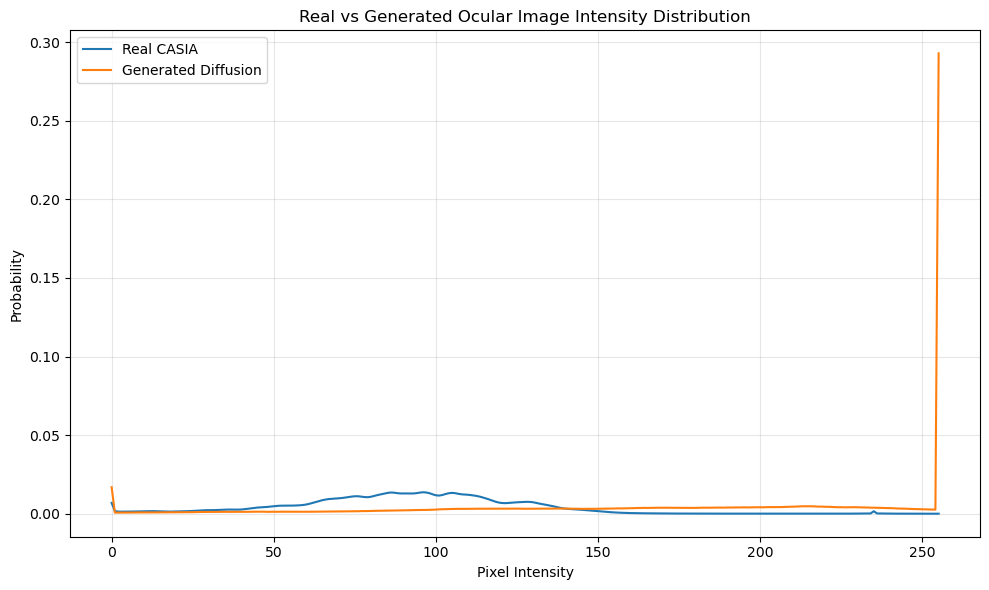


DISTRIBUTION COMPARISON
Real mean: 89.344548
Generated mean: 182.883475
Mean difference: 93.538927
Real std: 33.179507
Generated std: 72.612268
Std difference: 39.432761
Histogram intersection: 0.308855
Histogram L1 distance: 1.38229

Saved plot:
C:\Users\kavya\Downloads\Ocular_Project\results\notebook_08_quality_diversity\real_vs_generated_intensity_distribution.png

Cell 7 complete.


In [ ]:
# ============================================================
# Cell 7 — Recovery + Real vs Generated Distribution Plot
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# ------------------------------------------------------------
# Project paths
# ------------------------------------------------------------

PROJECT_ROOT = Path(
    r"C:\Users\kavya\Downloads\Ocular_Project"
)

OUTPUT_DIR = (
    PROJECT_ROOT
    / "results"
    / "notebook_08_quality_diversity"
)

# ------------------------------------------------------------
# Load previously saved histogram results
# ------------------------------------------------------------

histogram_path = (
    OUTPUT_DIR /
    "real_vs_generated_intensity_histogram.csv"
)

summary_path = (
    OUTPUT_DIR /
    "real_vs_generated_distribution_summary.csv"
)

print("Loading saved evaluation results...")

histogram_df = pd.read_csv(
    histogram_path
)

summary_df = pd.read_csv(
    summary_path
)

print("Histogram rows:", len(histogram_df))
print("Summary rows:", len(summary_df))

# ------------------------------------------------------------
# Extract distributions
# ------------------------------------------------------------

intensity = histogram_df["Intensity"].to_numpy()

real_hist_norm = (
    histogram_df["RealProbability"].to_numpy()
)

generated_hist_norm = (
    histogram_df["GeneratedProbability"].to_numpy()
)

# ------------------------------------------------------------
# Extract summary statistics
# ------------------------------------------------------------

real_row = summary_df[
    summary_df["Dataset"] == "Real"
].iloc[0]

generated_row = summary_df[
    summary_df["Dataset"] == "Generated"
].iloc[0]

real_mean = float(real_row["Mean"])
real_std = float(real_row["Std"])

generated_mean = float(
    generated_row["Mean"]
)

generated_std = float(
    generated_row["Std"]
)

# ------------------------------------------------------------
# Plot
# ------------------------------------------------------------

plt.figure(figsize=(10, 6))

plt.plot(
    intensity,
    real_hist_norm,
    label="Real CASIA"
)

plt.plot(
    intensity,
    generated_hist_norm,
    label="Generated Diffusion"
)

plt.xlabel("Pixel Intensity")
plt.ylabel("Probability")

plt.title(
    "Real vs Generated Ocular Image Intensity Distribution"
)

plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()

# ------------------------------------------------------------
# Save figure
# ------------------------------------------------------------

distribution_plot_path = (
    OUTPUT_DIR /
    "real_vs_generated_intensity_distribution.png"
)

plt.savefig(
    distribution_plot_path,
    dpi=200,
    bbox_inches="tight"
)

plt.show()

# ------------------------------------------------------------
# Print comparison
# ------------------------------------------------------------

print("\n" + "=" * 60)
print("DISTRIBUTION COMPARISON")
print("=" * 60)

print(
    "Real mean:",
    round(real_mean, 6)
)

print(
    "Generated mean:",
    round(generated_mean, 6)
)

print(
    "Mean difference:",
    round(
        generated_mean - real_mean,
        6
    )
)

print(
    "Real std:",
    round(real_std, 6)
)

print(
    "Generated std:",
    round(generated_std, 6)
)

print(
    "Std difference:",
    round(
        generated_std - real_std,
        6
    )
)

# ------------------------------------------------------------
# Histogram metrics
# ------------------------------------------------------------

histogram_intersection = np.minimum(
    real_hist_norm,
    generated_hist_norm
).sum()

histogram_l1 = np.abs(
    real_hist_norm -
    generated_hist_norm
).sum()

print(
    "Histogram intersection:",
    round(
        float(histogram_intersection),
        6
    )
)

print(
    "Histogram L1 distance:",
    round(
        float(histogram_l1),
        6
    )
)

print("\nSaved plot:")
print(distribution_plot_path)

print("\nCell 7 complete.")

In [ ]:
# ============================================================
# Cell 8 — Pretrained Feature Extractor Setup
# ============================================================

import torch
import torch.nn as nn
import torchvision
from torchvision import models, transforms

# ------------------------------------------------------------
# Device
# ------------------------------------------------------------

device = torch.device(
    "cuda" if torch.cuda.is_available()
    else "cpu"
)

print("Device:", device)

if torch.cuda.is_available():
    print(
        "GPU:",
        torch.cuda.get_device_name(0)
    )

# ------------------------------------------------------------
# Load pretrained ResNet-18
# ------------------------------------------------------------

print("\nLoading pretrained ResNet-18...")

weights = models.ResNet18_Weights.DEFAULT

resnet = models.resnet18(
    weights=weights
)

# Remove final classification layer
feature_extractor = nn.Sequential(
    *list(resnet.children())[:-1]
)

feature_extractor = (
    feature_extractor
    .to(device)
    .eval()
)

# ------------------------------------------------------------
# Freeze parameters
# ------------------------------------------------------------

for parameter in feature_extractor.parameters():
    parameter.requires_grad = False

# ------------------------------------------------------------
# Image preprocessing
# ------------------------------------------------------------

feature_transform = transforms.Compose([
    transforms.Resize(
        (224, 224)
    ),
    transforms.ToTensor(),
    transforms.Lambda(
        lambda x: x.repeat(3, 1, 1)
    ),
    transforms.Normalize(
        mean=[
            0.485,
            0.456,
            0.406
        ],
        std=[
            0.229,
            0.224,
            0.225
        ]
    )
])

print("\nFeature extractor:")
print("Architecture: ResNet-18")
print("Feature dimensionality: 512")
print("Input: grayscale ocular image replicated to 3 channels")
print("Weights: ImageNet pretrained")

print("\nCell 8 complete.")

Device: cuda
GPU: NVIDIA GeForce RTX 4060 Laptop GPU

Loading pretrained ResNet-18...

Feature extractor:
Architecture: ResNet-18
Feature dimensionality: 512
Input: grayscale ocular image replicated to 3 channels
Weights: ImageNet pretrained

Cell 8 complete.


In [ ]:
# ============================================================
# Cell 9 — Robust Real + Generated Feature Extraction
# ============================================================

import os
import numpy as np
import pandas as pd
from pathlib import Path
from PIL import Image

import torch
import torch.nn as nn
from torchvision import models, transforms

# ------------------------------------------------------------
# 1. Re-establish project paths
# ------------------------------------------------------------

PROJECT_ROOT = Path(
    r"C:\Users\kavya\Downloads\Ocular_Project"
)

DATASET_ROOT = (
    PROJECT_ROOT
    / "datasets"
    / "CASIA-Iris-Thousand"
    / "CASIA-Iris-Thousand"
)

CSV_PATH = (
    PROJECT_ROOT
    / "datasets"
    / "iris_thousands.csv"
)

GENERATION_DIR = (
    PROJECT_ROOT
    / "results"
    / "identity_conditioned_generation"
)

OUTPUT_DIR = (
    PROJECT_ROOT
    / "results"
    / "notebook_08_quality_diversity"
)

OUTPUT_DIR.mkdir(
    parents=True,
    exist_ok=True
)

# ------------------------------------------------------------
# 2. Device
# ------------------------------------------------------------

device = torch.device(
    "cuda" if torch.cuda.is_available()
    else "cpu"
)

print("Device:", device)

if torch.cuda.is_available():
    print(
        "GPU:",
        torch.cuda.get_device_name(0)
    )

# ------------------------------------------------------------
# 3. Load real dataset metadata
# ------------------------------------------------------------

df = pd.read_csv(
    CSV_PATH
)

def resolve_local_path(image_path):

    image_path = str(image_path)

    marker = "CASIA-Iris-Thousand"

    if marker in image_path:

        relative_part = (
            image_path
            .split(marker, 1)[1]
            .lstrip("\\/")
        )

        return DATASET_ROOT / relative_part

    return Path(image_path)


df["LocalPath"] = (
    df["ImagePath"]
    .apply(resolve_local_path)
)

real_df = df[
    ["Label", "LocalPath"]
].copy()

real_df = real_df.rename(
    columns={
        "Label": "Identity",
        "LocalPath": "Path"
    }
)

print("\nReal dataset:")
print("Images:", len(real_df))
print(
    "Identities:",
    real_df["Identity"].nunique()
)

# ------------------------------------------------------------
# 4. Locate generated PNG files recursively
# ------------------------------------------------------------

image_extensions = {
    ".png",
    ".jpg",
    ".jpeg"
}

generated_image_files = []

for root, dirs, files in os.walk(
    GENERATION_DIR
):

    for file in files:

        path = Path(root) / file

        if path.suffix.lower() in image_extensions:
            generated_image_files.append(path)

generated_image_files = sorted(
    generated_image_files
)

print("\nGenerated images found:")

print(
    len(generated_image_files)
)

# ------------------------------------------------------------
# 5. Build generated metadata
# ------------------------------------------------------------

generated_records = []

for path in generated_image_files:

    identity_folder = path.parent.name

    if not identity_folder.startswith(
        "identity_"
    ):
        continue

    identity_id = int(
        identity_folder.replace(
            "identity_",
            ""
        )
    )

    sample_id = int(
        path.stem.replace(
            "sample_",
            ""
        )
    )

    generated_records.append({
        "Identity": identity_id,
        "IdentityFolder": identity_folder,
        "Sample": sample_id,
        "Filename": path.name,
        "Path": str(path)
    })

generated_df = pd.DataFrame(
    generated_records
)

generated_df = (
    generated_df
    .sort_values(
        ["Identity", "Sample"]
    )
    .reset_index(drop=True)
)

print("\nGenerated metadata:")
print(
    generated_df.head()
)

print(
    "\nGenerated identities:",
    generated_df["Identity"].nunique()
)

print(
    "Generated samples:",
    len(generated_df)
)

# ------------------------------------------------------------
# 6. Load pretrained ResNet-18
# ------------------------------------------------------------

print("\nLoading pretrained ResNet-18...")

weights = models.ResNet18_Weights.DEFAULT

resnet = models.resnet18(
    weights=weights
)

feature_extractor = nn.Sequential(
    *list(resnet.children())[:-1]
)

feature_extractor = (
    feature_extractor
    .to(device)
    .eval()
)

for parameter in (
    feature_extractor.parameters()
):
    parameter.requires_grad = False

# ------------------------------------------------------------
# 7. Feature preprocessing
# ------------------------------------------------------------

feature_transform = transforms.Compose([
    transforms.Resize(
        (224, 224)
    ),
    transforms.ToTensor(),
    transforms.Lambda(
        lambda x: x.repeat(3, 1, 1)
    ),
    transforms.Normalize(
        mean=[
            0.485,
            0.456,
            0.406
        ],
        std=[
            0.229,
            0.224,
            0.225
        ]
    )
])

# ------------------------------------------------------------
# 8. Feature extraction function
# ------------------------------------------------------------

def extract_features(
    image_paths,
    batch_size=16
):

    features = []

    for start in range(
        0,
        len(image_paths),
        batch_size
    ):

        batch_paths = image_paths[
            start:start + batch_size
        ]

        batch_images = []

        for image_path in batch_paths:

            image = Image.open(
                image_path
            ).convert("L")

            tensor = feature_transform(
                image
            )

            batch_images.append(
                tensor
            )

        batch = torch.stack(
            batch_images
        ).to(device)

        with torch.no_grad():

            batch_features = (
                feature_extractor(batch)
                .flatten(1)
            )

        features.append(
            batch_features.cpu()
        )

    return torch.cat(
        features,
        dim=0
    ).numpy()

# ------------------------------------------------------------
# 9. Select balanced real reference set
# ------------------------------------------------------------

EVAL_SEED = 42

rng = np.random.default_rng(
    EVAL_SEED
)

real_identity_labels = sorted(
    real_df["Identity"].unique()
)

selected_real_identities = sorted(
    rng.choice(
        real_identity_labels,
        size=16,
        replace=False
    )
)

print(
    "\nSelected real identities:",
    selected_real_identities
)

real_feature_records = []

for identity in selected_real_identities:

    identity_rows = real_df[
        real_df["Identity"] == identity
    ]

    selected_rows = identity_rows.sample(
        n=min(
            40,
            len(identity_rows)
        ),
        random_state=EVAL_SEED
    )

    for _, row in selected_rows.iterrows():

        real_feature_records.append({
            "Identity": identity,
            "Path": row["Path"]
        })

real_feature_df = pd.DataFrame(
    real_feature_records
)

print(
    "Real evaluation images:",
    len(real_feature_df)
)

# ------------------------------------------------------------
# 10. Extract real features
# ------------------------------------------------------------

print(
    "\nExtracting real-image features..."
)

real_features = extract_features(
    real_feature_df["Path"].tolist(),
    batch_size=16
)

print(
    "Real feature matrix:",
    real_features.shape
)

# ------------------------------------------------------------
# 11. Extract generated features
# ------------------------------------------------------------

print(
    "\nExtracting generated-image features..."
)

generated_features = extract_features(
    generated_df["Path"].tolist(),
    batch_size=16
)

print(
    "Generated feature matrix:",
    generated_features.shape
)

# ------------------------------------------------------------
# 12. Numerical validation
# ------------------------------------------------------------

print("\nFeature validation:")

print(
    "Real finite:",
    np.isfinite(
        real_features
    ).all()
)

print(
    "Generated finite:",
    np.isfinite(
        generated_features
    ).all()
)

print(
    "Real feature mean:",
    round(
        float(real_features.mean()),
        6
    )
)

print(
    "Generated feature mean:",
    round(
        float(generated_features.mean()),
        6
    )
)

print(
    "Real feature std:",
    round(
        float(real_features.std()),
        6
    )
)

print(
    "Generated feature std:",
    round(
        float(generated_features.std()),
        6
    )
)

# ------------------------------------------------------------
# 13. Save features
# ------------------------------------------------------------

real_feature_path = (
    OUTPUT_DIR /
    "real_resnet18_features.npy"
)

generated_feature_path = (
    OUTPUT_DIR /
    "generated_resnet18_features.npy"
)

np.save(
    real_feature_path,
    real_features
)

np.save(
    generated_feature_path,
    generated_features
)

real_feature_df.to_csv(
    OUTPUT_DIR /
    "real_feature_evaluation_metadata.csv",
    index=False
)

generated_df.to_csv(
    OUTPUT_DIR /
    "generated_feature_evaluation_metadata.csv",
    index=False
)

print("\nSaved feature files:")

print(real_feature_path)
print(generated_feature_path)

print(
    OUTPUT_DIR /
    "real_feature_evaluation_metadata.csv"
)

print(
    OUTPUT_DIR /
    "generated_feature_evaluation_metadata.csv"
)

print("\nCell 9 complete.")

Device: cuda
GPU: NVIDIA GeForce RTX 4060 Laptop GPU

Real dataset:
Images: 20000
Identities: 2000

Generated images found:
64

Generated metadata:
   Identity IdentityFolder  Sample       Filename  \
0         0  identity_0000       1  sample_01.png   
1         0  identity_0000       2  sample_02.png   
2         0  identity_0000       3  sample_03.png   
3         0  identity_0000       4  sample_04.png   
4        79  identity_0079       1  sample_01.png   

                                                Path  
0  C:\Users\kavya\Downloads\Ocular_Project\result...  
1  C:\Users\kavya\Downloads\Ocular_Project\result...  
2  C:\Users\kavya\Downloads\Ocular_Project\result...  
3  C:\Users\kavya\Downloads\Ocular_Project\result...  
4  C:\Users\kavya\Downloads\Ocular_Project\result...  

Generated identities: 16
Generated samples: 64

Loading pretrained ResNet-18...

Selected real identities: [np.str_('085-R'), np.str_('088-R'), np.str_('093-R'), np.str_('200-R'), np.str_('430-R'), np.s

In [ ]:
# ============================================================
# Cell 10 — Feature-Space Quality and Diversity Analysis
# ============================================================

import numpy as np
import pandas as pd
from pathlib import Path

# ------------------------------------------------------------
# Reload saved features
# ------------------------------------------------------------

real_features = np.load(
    OUTPUT_DIR /
    "real_resnet18_features.npy"
)

generated_features = np.load(
    OUTPUT_DIR /
    "generated_resnet18_features.npy"
)

generated_meta = pd.read_csv(
    OUTPUT_DIR /
    "generated_feature_evaluation_metadata.csv"
)

print("Real features:", real_features.shape)
print("Generated features:", generated_features.shape)

# ------------------------------------------------------------
# L2 normalization
# ------------------------------------------------------------

def l2_normalize(features):

    norms = np.linalg.norm(
        features,
        axis=1,
        keepdims=True
    )

    return features / np.maximum(
        norms,
        1e-12
    )


real_norm = l2_normalize(
    real_features
)

generated_norm = l2_normalize(
    generated_features
)

# ------------------------------------------------------------
# Pairwise cosine similarity matrix
# ------------------------------------------------------------

real_similarity = (
    real_norm @ real_norm.T
)

generated_similarity = (
    generated_norm @ generated_norm.T
)

# ------------------------------------------------------------
# Remove diagonal self-similarity
# ------------------------------------------------------------

real_mask = ~np.eye(
    len(real_similarity),
    dtype=bool
)

generated_mask = ~np.eye(
    len(generated_similarity),
    dtype=bool
)

real_pairwise_similarity = (
    real_similarity[real_mask]
)

generated_pairwise_similarity = (
    generated_similarity[generated_mask]
)

# ------------------------------------------------------------
# Convert cosine similarity to cosine distance
# ------------------------------------------------------------

real_pairwise_distance = (
    1.0 -
    real_pairwise_similarity
)

generated_pairwise_distance = (
    1.0 -
    generated_pairwise_similarity
)

# ------------------------------------------------------------
# Cross-distribution similarity
# ------------------------------------------------------------

cross_similarity = (
    generated_norm @ real_norm.T
)

cross_distance = (
    1.0 -
    cross_similarity
)

# ------------------------------------------------------------
# Generated identity-aware diversity
# ------------------------------------------------------------

within_identity_distances = []
between_identity_distances = []

generated_identity_values = (
    generated_meta["Identity"]
    .to_numpy()
)

for i in range(
    len(generated_norm)
):

    for j in range(
        i + 1,
        len(generated_norm)
    ):

        distance = (
            1.0 -
            np.dot(
                generated_norm[i],
                generated_norm[j]
            )
        )

        if (
            generated_identity_values[i]
            ==
            generated_identity_values[j]
        ):

            within_identity_distances.append(
                distance
            )

        else:

            between_identity_distances.append(
                distance
            )

within_identity_distances = np.asarray(
    within_identity_distances
)

between_identity_distances = np.asarray(
    between_identity_distances
)

# ------------------------------------------------------------
# Feature variance
# ------------------------------------------------------------

real_feature_variance = (
    np.var(
        real_features,
        axis=0
    )
)

generated_feature_variance = (
    np.var(
        generated_features,
        axis=0
    )
)

real_mean_feature_variance = (
    real_feature_variance.mean()
)

generated_mean_feature_variance = (
    generated_feature_variance.mean()
)

# ------------------------------------------------------------
# Summary statistics helper
# ------------------------------------------------------------

def summarize(values):

    values = np.asarray(
        values,
        dtype=np.float64
    )

    return {
        "Mean": float(
            np.mean(values)
        ),
        "Std": float(
            np.std(values)
        ),
        "Min": float(
            np.min(values)
        ),
        "Median": float(
            np.median(values)
        ),
        "Max": float(
            np.max(values)
        )
    }

# ------------------------------------------------------------
# Calculate summaries
# ------------------------------------------------------------

real_diversity_summary = summarize(
    real_pairwise_distance
)

generated_diversity_summary = summarize(
    generated_pairwise_distance
)

cross_distance_summary = summarize(
    cross_distance.ravel()
)

within_identity_summary = summarize(
    within_identity_distances
)

between_identity_summary = summarize(
    between_identity_distances
)

# ------------------------------------------------------------
# Print results
# ------------------------------------------------------------

print("\n" + "=" * 65)
print("FEATURE-SPACE DIVERSITY")
print("=" * 65)

print("\nReal pairwise cosine distance:")
for key, value in real_diversity_summary.items():
    print(
        f"{key:10s}: {value:.6f}"
    )

print("\nGenerated pairwise cosine distance:")
for key, value in generated_diversity_summary.items():
    print(
        f"{key:10s}: {value:.6f}"
    )

print("\nGenerated within-identity distance:")
for key, value in within_identity_summary.items():
    print(
        f"{key:10s}: {value:.6f}"
    )

print("\nGenerated between-identity distance:")
for key, value in between_identity_summary.items():
    print(
        f"{key:10s}: {value:.6f}"
    )

print("\nReal-to-generated feature distance:")
for key, value in cross_distance_summary.items():
    print(
        f"{key:10s}: {value:.6f}"
    )

print("\n" + "=" * 65)
print("FEATURE VARIANCE")
print("=" * 65)

print(
    "Real mean feature variance:",
    round(
        real_mean_feature_variance,
        6
    )
)

print(
    "Generated mean feature variance:",
    round(
        generated_mean_feature_variance,
        6
    )
)

# ------------------------------------------------------------
# Save summary table
# ------------------------------------------------------------

feature_summary_rows = [

    {
        "Comparison": "Real pairwise",
        **real_diversity_summary
    },

    {
        "Comparison": "Generated pairwise",
        **generated_diversity_summary
    },

    {
        "Comparison": "Generated within identity",
        **within_identity_summary
    },

    {
        "Comparison": "Generated between identity",
        **between_identity_summary
    },

    {
        "Comparison": "Real to generated",
        **cross_distance_summary
    }
]

feature_summary_df = pd.DataFrame(
    feature_summary_rows
)

feature_summary_df.to_csv(
    OUTPUT_DIR /
    "feature_space_diversity_summary.csv",
    index=False
)

# ------------------------------------------------------------
# Save feature variance summary
# ------------------------------------------------------------

variance_summary_df = pd.DataFrame([
    {
        "Dataset": "Real",
        "MeanFeatureVariance":
            real_mean_feature_variance
    },
    {
        "Dataset": "Generated",
        "MeanFeatureVariance":
            generated_mean_feature_variance
    }
])

variance_summary_df.to_csv(
    OUTPUT_DIR /
    "feature_variance_summary.csv",
    index=False
)

print("\nSaved:")
print(
    OUTPUT_DIR /
    "feature_space_diversity_summary.csv"
)

print(
    OUTPUT_DIR /
    "feature_variance_summary.csv"
)

print("\nCell 10 complete.")

Real features: (160, 512)
Generated features: (64, 512)

FEATURE-SPACE DIVERSITY

Real pairwise cosine distance:
Mean      : 0.147181
Std       : 0.054041
Min       : 0.004031
Median    : 0.148219
Max       : 0.354663

Generated pairwise cosine distance:
Mean      : 0.293958
Std       : 0.132746
Min       : 0.054638
Median    : 0.276558
Max       : 0.626646

Generated within-identity distance:
Mean      : 0.284650
Std       : 0.138216
Min       : 0.080657
Median    : 0.265573
Max       : 0.608534

Generated between-identity distance:
Mean      : 0.294423
Std       : 0.132449
Min       : 0.054637
Median    : 0.276777
Max       : 0.626646

Real-to-generated feature distance:
Mean      : 0.331737
Std       : 0.121547
Min       : 0.057804
Median    : 0.306104
Max       : 0.618123

FEATURE VARIANCE
Real mean feature variance: 0.251663
Generated mean feature variance: 0.359515

Saved:
C:\Users\kavya\Downloads\Ocular_Project\results\notebook_08_quality_diversity\feature_space_diversity_summar

In [ ]:
# ============================================================
# Cell 11 — Fréchet Distance (FID-style) in ResNet-18 Space
# ============================================================

import numpy as np
import pandas as pd

# ------------------------------------------------------------
# Load saved feature matrices
# ------------------------------------------------------------

real_features = np.load(
    OUTPUT_DIR /
    "real_resnet18_features.npy"
)

generated_features = np.load(
    OUTPUT_DIR /
    "generated_resnet18_features.npy"
)

print(
    "Real features:",
    real_features.shape
)

print(
    "Generated features:",
    generated_features.shape
)

# ------------------------------------------------------------
# Calculate feature means
# ------------------------------------------------------------

mu_real = np.mean(
    real_features,
    axis=0
)

mu_generated = np.mean(
    generated_features,
    axis=0
)

# ------------------------------------------------------------
# Calculate covariance matrices
# ------------------------------------------------------------

sigma_real = np.cov(
    real_features,
    rowvar=False
)

sigma_generated = np.cov(
    generated_features,
    rowvar=False
)

print(
    "\nCovariance shape:",
    sigma_real.shape
)

# ------------------------------------------------------------
# Matrix square root helper
# ------------------------------------------------------------

def matrix_sqrt_psd(matrix):

    matrix = (
        matrix +
        matrix.T
    ) / 2.0

    eigenvalues, eigenvectors = (
        np.linalg.eigh(matrix)
    )

    eigenvalues = np.clip(
        eigenvalues,
        0,
        None
    )

    sqrt_matrix = (
        eigenvectors
        @ np.diag(
            np.sqrt(eigenvalues)
        )
        @ eigenvectors.T
    )

    return sqrt_matrix

# ------------------------------------------------------------
# Fréchet distance calculation
# ------------------------------------------------------------

mean_difference = (
    mu_real -
    mu_generated
)

mean_term = np.dot(
    mean_difference,
    mean_difference
)

# Stable PSD square roots
sqrt_real = matrix_sqrt_psd(
    sigma_real
)

middle_matrix = (
    sqrt_real
    @ sigma_generated
    @ sqrt_real
)

sqrt_middle = matrix_sqrt_psd(
    middle_matrix
)

covariance_term = (
    np.trace(
        sigma_real
    )
    +
    np.trace(
        sigma_generated
    )
    -
    2.0 *
    np.trace(
        sqrt_middle
    )
)

fid_value = (
    mean_term +
    covariance_term
)

# Numerical cleanup
fid_value = max(
    float(fid_value),
    0.0
)

# ------------------------------------------------------------
# Print result
# ------------------------------------------------------------

print("\n" + "=" * 65)
print("FEATURE-SPACE FRÉCHET DISTANCE")
print("=" * 65)

print(
    "Mean term:",
    round(
        mean_term,
        6
    )
)

print(
    "Covariance term:",
    round(
        covariance_term,
        6
    )
)

print(
    "FID-style distance:",
    round(
        fid_value,
        6
    )
)

print("\nImportant:")
print(
    "This is a Fréchet distance computed in "
    "ImageNet-pretrained ResNet-18 feature space."
)

print(
    "It is NOT the standard Inception-v3 FID."
)

# ------------------------------------------------------------
# Save result
# ------------------------------------------------------------

fid_summary = pd.DataFrame([
    {
        "Metric":
            "Frechet Distance",
        "FeatureExtractor":
            "ImageNet ResNet-18",
        "RealSamples":
            len(real_features),
        "GeneratedSamples":
            len(generated_features),
        "Value":
            fid_value
    }
])

fid_summary.to_csv(
    OUTPUT_DIR /
    "feature_space_fid_summary.csv",
    index=False
)

print("\nSaved:")
print(
    OUTPUT_DIR /
    "feature_space_fid_summary.csv"
)

print("\nCell 11 complete.")

Real features: (160, 512)
Generated features: (64, 512)

Covariance shape: (512, 512)

FEATURE-SPACE FRÉCHET DISTANCE
Mean term: 182.28633
Covariance term: 163.749086
FID-style distance: 346.035417

Important:
This is a Fréchet distance computed in ImageNet-pretrained ResNet-18 feature space.
It is NOT the standard Inception-v3 FID.

Saved:
C:\Users\kavya\Downloads\Ocular_Project\results\notebook_08_quality_diversity\feature_space_fid_summary.csv

Cell 11 complete.


In [ ]:
# ============================================================
# Cell 12 — Check LPIPS / Perceptual Metric Availability
# ============================================================

import importlib.util

packages_to_check = [
    "torchmetrics",
    "lpips",
    "torch_fidelity"
]

print("Checking perceptual-metric packages...\n")

for package in packages_to_check:

    available = (
        importlib.util.find_spec(package)
        is not None
    )

    status = (
        "✓ AVAILABLE"
        if available
        else "✗ NOT INSTALLED"
    )

    print(
        f"{package:20s}: {status}"
    )

print("\nCell 12 complete.")

Checking perceptual-metric packages...

torchmetrics        : ✗ NOT INSTALLED
lpips               : ✗ NOT INSTALLED
torch_fidelity      : ✗ NOT INSTALLED

Cell 12 complete.


In [ ]:
# ============================================================
# Cell 13 — Install LPIPS Package
# ============================================================

import sys
import subprocess

print("Installing LPIPS...")

result = subprocess.run(
    [
        sys.executable,
        "-m",
        "pip",
        "install",
        "lpips"
    ],
    capture_output=True,
    text=True
)

print(result.stdout)

if result.returncode == 0:
    print("\n✓ LPIPS installed successfully.")
else:
    print("\n✗ LPIPS installation failed.")
    print(result.stderr)

print("\nCell 13 complete.")

Installing LPIPS...


✓ LPIPS installed successfully.

Cell 13 complete.


In [ ]:
# ============================================================
# Cell 14D — Fix Real LPIPS Resolution
# ============================================================

import os
import numpy as np
import torch
from PIL import Image

TARGET_SIZE = (224, 224)

print("Fixing real reference images for LPIPS...")
print(f"Target size: {TARGET_SIZE}")

# Use the real reference dataframe already created by Cell 14B
assert "real_reference_df" in globals(), \
    "real_reference_df not found. Run Cell 14B once first."

# Load real images and FORCE resize to 224x224
fixed_real_tensors = []

for path in real_reference_df["LocalPath"]:

    img = Image.open(path).convert("L")

    img = img.resize(
        TARGET_SIZE,
        Image.Resampling.BILINEAR
    )

    arr = np.asarray(
        img,
        dtype=np.float32
    ) / 255.0

    tensor = torch.from_numpy(arr)

    # grayscale -> 3 channels
    tensor = tensor.unsqueeze(0).repeat(3, 1, 1)

    # batch dimension
    tensor = tensor.unsqueeze(0)

    # [0,1] -> [-1,1]
    tensor = tensor * 2.0 - 1.0

    fixed_real_tensors.append(tensor)

real_reference_tensors = torch.cat(
    fixed_real_tensors,
    dim=0
).to(device)

print(
    "Generated tensor shape:",
    tuple(generated_tensors.shape)
)

print(
    "FIXED real tensor shape:",
    tuple(real_reference_tensors.shape)
)

# Hard verification
assert generated_tensors.shape[2:] == real_reference_tensors.shape[2:], \
    "Resolution mismatch still exists!"

print("\n✓ Resolution check passed.")
print("Both generated and real images are now 224 × 224.")
print("\nCell 14D complete.")

Fixing real reference images for LPIPS...
Target size: (224, 224)
Generated tensor shape: (64, 3, 224, 224)
FIXED real tensor shape: (64, 3, 224, 224)

✓ Resolution check passed.
Both generated and real images are now 224 × 224.

Cell 14D complete.


In [ ]:
# ============================================================
# Cell 14E — Final LPIPS Calculation
# ============================================================

from itertools import combinations
import numpy as np
import pandas as pd
import os

print("=" * 70)
print("FINAL LPIPS CALCULATION")
print("=" * 70)

# ------------------------------------------------------------
# Verify required variables
# ------------------------------------------------------------
required = [
    "loss_fn",
    "generated_tensors",
    "real_reference_tensors",
    "generated_identities",
    "unique_ids"
]

missing = [
    x for x in required
    if x not in globals()
]

if missing:
    raise RuntimeError(
        f"Missing variables: {missing}"
    )

# Final resolution safety check
assert (
    generated_tensors.shape[2:]
    ==
    real_reference_tensors.shape[2:]
)

print(
    f"\nGenerated: {tuple(generated_tensors.shape)}"
)

print(
    f"Real reference: "
    f"{tuple(real_reference_tensors.shape)}"
)

# ------------------------------------------------------------
# Pairwise LPIPS helper
# ------------------------------------------------------------
def lpips_pairs(
    tensors_a,
    tensors_b,
    pairs,
    batch_size=16
):

    results = []

    with torch.no_grad():

        for start in range(
            0,
            len(pairs),
            batch_size
        ):

            batch = pairs[
                start:start + batch_size
            ]

            a_idx = [
                p[0] for p in batch
            ]

            b_idx = [
                p[1] for p in batch
            ]

            distances = loss_fn(
                tensors_a[a_idx],
                tensors_b[b_idx]
            ).reshape(-1)

            results.extend(
                distances
                .detach()
                .cpu()
                .numpy()
            )

    return np.asarray(
        results,
        dtype=np.float64
    )

# ------------------------------------------------------------
# 1. WITHIN-IDENTITY
# ------------------------------------------------------------
print("\n[1/3] Within-identity LPIPS...")

within_pairs = []

for identity in unique_ids:

    indices = [
        i
        for i, x in enumerate(
            generated_identities
        )
        if x == identity
    ]

    within_pairs.extend(
        list(combinations(indices, 2))
    )

print(
    f"Pairs: {len(within_pairs)}"
)

within = lpips_pairs(
    generated_tensors,
    generated_tensors,
    within_pairs
)

print(
    f"Mean: {within.mean():.6f}"
)

# ------------------------------------------------------------
# 2. BETWEEN-IDENTITY
# ------------------------------------------------------------
print("\n[2/3] Between-identity LPIPS...")

between_pairs = []

for id_a, id_b in combinations(
    unique_ids,
    2
):

    a_indices = [
        i
        for i, x in enumerate(
            generated_identities
        )
        if x == id_a
    ]

    b_indices = [
        i
        for i, x in enumerate(
            generated_identities
        )
        if x == id_b
    ]

    for i in a_indices:
        for j in b_indices:
            between_pairs.append(
                (i, j)
            )

print(
    f"Pairs: {len(between_pairs)}"
)

between = lpips_pairs(
    generated_tensors,
    generated_tensors,
    between_pairs
)

print(
    f"Mean: {between.mean():.6f}"
)

# ------------------------------------------------------------
# 3. REAL vs GENERATED
# ------------------------------------------------------------
print("\n[3/3] Real-vs-generated LPIPS...")

real_generated_pairs = [
    (i, j)
    for i in range(
        len(generated_tensors)
    )
    for j in range(
        len(real_reference_tensors)
    )
]

print(
    f"Pairs: {len(real_generated_pairs)}"
)

real_generated = lpips_pairs(
    generated_tensors,
    real_reference_tensors,
    real_generated_pairs
)

print(
    f"Mean: {real_generated.mean():.6f}"
)

# ------------------------------------------------------------
# Statistics
# ------------------------------------------------------------
def stats(x):

    return {
        "N": len(x),
        "Mean": float(x.mean()),
        "Std": float(x.std()),
        "Min": float(x.min()),
        "Median": float(np.median(x)),
        "Max": float(x.max())
    }

summary = pd.DataFrame([
    {
        "Metric":
            "Generated within-identity LPIPS",
        **stats(within)
    },
    {
        "Metric":
            "Generated between-identity LPIPS",
        **stats(between)
    },
    {
        "Metric":
            "Real-vs-generated LPIPS",
        **stats(real_generated)
    }
])

# ------------------------------------------------------------
# Diversity gap
# ------------------------------------------------------------
diversity_gap = (
    between.mean()
    -
    within.mean()
)

# ------------------------------------------------------------
# Print final result
# ------------------------------------------------------------
print("\n" + "=" * 70)
print("LPIPS RESULTS")
print("=" * 70)

print(
    summary.to_string(index=False)
)

print(
    f"\nBetween - Within diversity gap: "
    f"{diversity_gap:.6f}"
)

# ------------------------------------------------------------
# Save
# ------------------------------------------------------------
OUTPUT_DIR = os.path.join(
    PROJECT_ROOT,
    "results",
    "notebook_08_quality_diversity"
)

summary_path = os.path.join(
    OUTPUT_DIR,
    "lpips_summary.csv"
)

summary.to_csv(
    summary_path,
    index=False
)

raw_path = os.path.join(
    OUTPUT_DIR,
    "lpips_raw_distances.npz"
)

np.savez_compressed(
    raw_path,
    within_identity=within,
    between_identity=between,
    real_generated=real_generated
)

print(
    f"\nSaved: {summary_path}"
)

print(
    f"Saved: {raw_path}"
)

print("\n✓ Cell 14E complete.")

FINAL LPIPS CALCULATION

Generated: (64, 3, 224, 224)
Real reference: (64, 3, 224, 224)

[1/3] Within-identity LPIPS...
Pairs: 96
Mean: 0.582470

[2/3] Between-identity LPIPS...
Pairs: 1920
Mean: 0.591881

[3/3] Real-vs-generated LPIPS...
Pairs: 4096
Mean: 0.654894

LPIPS RESULTS
                          Metric    N     Mean      Std      Min   Median      Max
 Generated within-identity LPIPS   96 0.582470 0.175479 0.130334 0.585021 0.932551
Generated between-identity LPIPS 1920 0.591881 0.171502 0.026465 0.586266 0.935584
         Real-vs-generated LPIPS 4096 0.654894 0.147838 0.268840 0.627550 0.921902

Between - Within diversity gap: 0.009411

Saved: C:\Users\kavya\Downloads\Ocular_Project\results\notebook_08_quality_diversity\lpips_summary.csv
Saved: C:\Users\kavya\Downloads\Ocular_Project\results\notebook_08_quality_diversity\lpips_raw_distances.npz

✓ Cell 14E complete.


In [ ]:
# ============================================================
# Cell 15 — Check SSIM / PSNR Availability
# ============================================================

import importlib.util

print("=" * 70)
print("CHECKING SSIM / PSNR SUPPORT")
print("=" * 70)

packages_to_check = {
    "skimage": "scikit-image",
    "torchmetrics": "torchmetrics"
}

for module_name, package_name in packages_to_check.items():

    available = (
        importlib.util.find_spec(module_name)
        is not None
    )

    status = (
        "✓ AVAILABLE"
        if available
        else "✗ NOT INSTALLED"
    )

    print(
        f"{package_name:20s}: {status}"
    )

print("\nCell 15 complete.")

CHECKING SSIM / PSNR SUPPORT
scikit-image        : ✓ AVAILABLE
torchmetrics        : ✗ NOT INSTALLED

Cell 15 complete.


In [ ]:
# ============================================================
# Cell 16 — SSIM / PSNR Within Generated Identities
# ============================================================

import os
import numpy as np
import pandas as pd
from PIL import Image
from itertools import combinations
from skimage.metrics import structural_similarity, peak_signal_noise_ratio

print("=" * 70)
print("SSIM / PSNR — GENERATED WITHIN-IDENTITY ANALYSIS")
print("=" * 70)

# ------------------------------------------------------------
# Paths
# ------------------------------------------------------------
PROJECT_ROOT = r"C:\Users\kavya\Downloads\Ocular_Project"

GENERATION_DIR = os.path.join(
    PROJECT_ROOT,
    "results",
    "identity_conditioned_generation"
)

OUTPUT_DIR = os.path.join(
    PROJECT_ROOT,
    "results",
    "notebook_08_quality_diversity"
)

os.makedirs(OUTPUT_DIR, exist_ok=True)

# ------------------------------------------------------------
# Locate generated images
# ------------------------------------------------------------
generated_files = []

for root, dirs, files in os.walk(GENERATION_DIR):
    for file in files:
        if file.lower().endswith(".png"):
            generated_files.append(
                os.path.join(root, file)
            )

generated_files = sorted(generated_files)

print(
    f"\nGenerated images found: "
    f"{len(generated_files)}"
)

assert len(generated_files) == 64

# ------------------------------------------------------------
# Load grayscale images at native generated resolution
# ------------------------------------------------------------
images = []
identities = []

for path in generated_files:

    img = Image.open(path).convert("L")

    arr = np.asarray(
        img,
        dtype=np.float32
    ) / 255.0

    images.append(arr)

    parent = os.path.basename(
        os.path.dirname(path)
    )

    identities.append(parent)

images = np.asarray(images)

print(
    f"Image tensor shape: "
    f"{images.shape}"
)

print(
    f"Unique identities: "
    f"{len(set(identities))}"
)

# ------------------------------------------------------------
# Compute pairwise SSIM / PSNR
# ------------------------------------------------------------
ssim_values = []
psnr_values = []

pair_records = []

for identity in sorted(set(identities)):

    indices = [
        i
        for i, x in enumerate(identities)
        if x == identity
    ]

    pairs = list(
        combinations(indices, 2)
    )

    for i, j in pairs:

        img_a = images[i]
        img_b = images[j]

        ssim = structural_similarity(
            img_a,
            img_b,
            data_range=1.0
        )

        psnr = peak_signal_noise_ratio(
            img_a,
            img_b,
            data_range=1.0
        )

        ssim_values.append(ssim)
        psnr_values.append(psnr)

        pair_records.append({
            "Identity": identity,
            "ImageA": os.path.basename(
                generated_files[i]
            ),
            "ImageB": os.path.basename(
                generated_files[j]
            ),
            "SSIM": ssim,
            "PSNR_dB": psnr
        })

# ------------------------------------------------------------
# Convert to arrays
# ------------------------------------------------------------
ssim_values = np.asarray(
    ssim_values,
    dtype=np.float64
)

psnr_values = np.asarray(
    psnr_values,
    dtype=np.float64
)

# ------------------------------------------------------------
# Summary
# ------------------------------------------------------------
summary = pd.DataFrame([
    {
        "Metric":
            "Generated within-identity SSIM",
        "N": len(ssim_values),
        "Mean": ssim_values.mean(),
        "Std": ssim_values.std(),
        "Min": ssim_values.min(),
        "Median": np.median(ssim_values),
        "Max": ssim_values.max()
    },
    {
        "Metric":
            "Generated within-identity PSNR (dB)",
        "N": len(psnr_values),
        "Mean": psnr_values.mean(),
        "Std": psnr_values.std(),
        "Min": psnr_values.min(),
        "Median": np.median(psnr_values),
        "Max": psnr_values.max()
    }
])

# ------------------------------------------------------------
# Print
# ------------------------------------------------------------
print("\n" + "=" * 70)
print("SSIM / PSNR RESULTS")
print("=" * 70)

print(
    summary.to_string(index=False)
)

# ------------------------------------------------------------
# Save summary
# ------------------------------------------------------------
summary_path = os.path.join(
    OUTPUT_DIR,
    "generated_within_identity_ssim_psnr_summary.csv"
)

summary.to_csv(
    summary_path,
    index=False
)

# ------------------------------------------------------------
# Save raw pair results
# ------------------------------------------------------------
pair_path = os.path.join(
    OUTPUT_DIR,
    "generated_within_identity_ssim_psnr_pairs.csv"
)

pd.DataFrame(
    pair_records
).to_csv(
    pair_path,
    index=False
)

print(
    f"\nSaved summary:\n{summary_path}"
)

print(
    f"\nSaved pair-level results:\n{pair_path}"
)

print("\nCell 16 complete.")

SSIM / PSNR — GENERATED WITHIN-IDENTITY ANALYSIS

Generated images found: 64
Image tensor shape: (64, 224, 224)
Unique identities: 16

SSIM / PSNR RESULTS
                             Metric  N      Mean      Std      Min    Median       Max
     Generated within-identity SSIM 96  0.548737 0.178265 0.182056  0.567617  0.929361
Generated within-identity PSNR (dB) 96 11.840113 6.323253 1.212931 11.426620 27.214217

Saved summary:
C:\Users\kavya\Downloads\Ocular_Project\results\notebook_08_quality_diversity\generated_within_identity_ssim_psnr_summary.csv

Saved pair-level results:
C:\Users\kavya\Downloads\Ocular_Project\results\notebook_08_quality_diversity\generated_within_identity_ssim_psnr_pairs.csv

Cell 16 complete.


In [ ]:
# ============================================================
# Cell 17 — Notebook 8 Consolidated Results
# ============================================================

import os
import json
import pandas as pd
import numpy as np

print("=" * 70)
print("NOTEBOOK 8 — CONSOLIDATED QUALITY & DIVERSITY RESULTS")
print("=" * 70)

PROJECT_ROOT = r"C:\Users\kavya\Downloads\Ocular_Project"

OUTPUT_DIR = os.path.join(
    PROJECT_ROOT,
    "results",
    "notebook_08_quality_diversity"
)

# ------------------------------------------------------------
# Load saved evaluation summaries
# ------------------------------------------------------------

files = {
    "distribution":
        "real_vs_generated_distribution_summary.csv",

    "feature_diversity":
        "feature_space_diversity_summary.csv",

    "feature_variance":
        "feature_variance_summary.csv",

    "feature_frechet":
        "feature_space_fid_summary.csv",

    "lpips":
        "lpips_summary.csv",

    "ssim_psnr":
        "generated_within_identity_ssim_psnr_summary.csv"
}

loaded = {}

for key, filename in files.items():

    path = os.path.join(
        OUTPUT_DIR,
        filename
    )

    if os.path.exists(path):

        loaded[key] = pd.read_csv(path)

        print(
            f"✓ Loaded: {filename}"
        )

    else:

        print(
            f"✗ Missing: {filename}"
        )

# ------------------------------------------------------------
# Print loaded summaries
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("AVAILABLE RESULTS")
print("=" * 70)

for key, df in loaded.items():

    print(
        f"\n--- {key.upper()} ---"
    )

    print(
        df.to_string(index=False)
    )

# ------------------------------------------------------------
# Build machine-readable summary
# ------------------------------------------------------------

final_summary = {
    "experiment": "Notebook 8 — Image Quality and Diversity Evaluation",
    "dataset": "CASIA-Iris-Thousand",
    "generated_images": 64,
    "generated_identities": 16,
    "samples_per_generated_identity": 4,

    "metrics": {
        "intensity_distribution": "completed",
        "resnet18_feature_diversity": "completed",
        "resnet18_feature_frechet_distance": "completed",
        "lpips": "completed",
        "ssim": "completed",
        "psnr": "completed"
    },

    "methodological_notes": [
        "Real-vs-generated PSNR/SSIM was not used as a paired reconstruction metric.",
        "LPIPS real-vs-generated comparison is distribution-level because images are not paired.",
        "Feature-space Frechet distance was computed using ImageNet-pretrained ResNet-18 features, not standard Inception-v3 FID.",
        "ResNet-18 feature analysis is a generic visual feature proxy, not a dedicated ocular biometric network.",
        "Generated identity labels correspond to the conditional model's embedding indices and were not treated as CASIA biometric labels.",
        "Within-identity versus between-identity metrics are descriptive measures of generated variation and identity separation."
    ]
}

# ------------------------------------------------------------
# Add key numerical values
# ------------------------------------------------------------

# LPIPS
if "lpips" in loaded:

    lpips_df = loaded["lpips"]

    for _, row in lpips_df.iterrows():

        metric = row["Metric"]

        if "within" in metric.lower():
            final_summary["lpips_within_identity_mean"] = float(
                row["Mean"]
            )

        elif "between" in metric.lower():
            final_summary["lpips_between_identity_mean"] = float(
                row["Mean"]
            )

        elif "real-vs-generated" in metric.lower():
            final_summary["lpips_real_generated_mean"] = float(
                row["Mean"]
            )

# SSIM / PSNR
if "ssim_psnr" in loaded:

    ssim_df = loaded["ssim_psnr"]

    for _, row in ssim_df.iterrows():

        metric = row["Metric"]

        if "SSIM" in metric:
            final_summary["ssim_within_identity_mean"] = float(
                row["Mean"]
            )

        elif "PSNR" in metric:
            final_summary["psnr_within_identity_mean_db"] = float(
                row["Mean"]
            )

# ------------------------------------------------------------
# Save JSON
# ------------------------------------------------------------

json_path = os.path.join(
    OUTPUT_DIR,
    "NOTEBOOK_08_FINAL_SUMMARY.json"
)

with open(
    json_path,
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        final_summary,
        f,
        indent=4
    )

# ------------------------------------------------------------
# Save CSV key-results table
# ------------------------------------------------------------

key_results = []

for key, value in final_summary.items():

    if isinstance(value, (int, float)):

        key_results.append({
            "Metric": key,
            "Value": value
        })

key_results_df = pd.DataFrame(
    key_results
)

csv_path = os.path.join(
    OUTPUT_DIR,
    "NOTEBOOK_08_FINAL_KEY_RESULTS.csv"
)

key_results_df.to_csv(
    csv_path,
    index=False
)

# ------------------------------------------------------------
# Final output
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("NOTEBOOK 8 FINAL KEY RESULTS")
print("=" * 70)

print(
    key_results_df.to_string(
        index=False
    )
)

print(
    f"\nSaved JSON:\n{json_path}"
)

print(
    f"\nSaved CSV:\n{csv_path}"
)

print("\n✓ Cell 17 complete.")
print("✓ Notebook 8 evaluation consolidated.")

NOTEBOOK 8 — CONSOLIDATED QUALITY & DIVERSITY RESULTS
✓ Loaded: real_vs_generated_distribution_summary.csv
✓ Loaded: feature_space_diversity_summary.csv
✓ Loaded: feature_variance_summary.csv
✓ Loaded: feature_space_fid_summary.csv
✓ Loaded: lpips_summary.csv
✓ Loaded: generated_within_identity_ssim_psnr_summary.csv

AVAILABLE RESULTS

--- DISTRIBUTION ---
  Dataset  Images  TotalPixels       Mean       Std  Min  Max  P01  P05   P25   P50   P75   P95   P99
     Real   20000   6144000000  89.344548 33.179507    0  255  3.0 29.0  70.0  91.0 111.0 138.0 156.0
Generated      64      3211264 182.883475 72.612268    0  255  0.0 36.0 131.0 201.0 255.0 255.0 255.0

--- FEATURE_DIVERSITY ---
                Comparison     Mean      Std      Min   Median      Max
             Real pairwise 0.147181 0.054041 0.004031 0.148219 0.354663
        Generated pairwise 0.293958 0.132746 0.054638 0.276558 0.626646
 Generated within identity 0.284650 0.138216 0.080657 0.265573 0.608534
Generated between id

# Final Evaluation Summary

| Evaluation | Result |
|---|---:|
| Generated samples | 64 |
| Generated identities | 16 |
| Samples per identity | 4 |
| Real mean intensity | 89.34 |
| Generated mean intensity | 182.88 |
| Real standard deviation | 33.18 |
| Generated standard deviation | 72.61 |
| Histogram intersection | 0.3089 |
| Feature-space Fréchet distance | 346.04 |
| Generated within-identity LPIPS | 0.5825 |
| Generated between-identity LPIPS | 0.5919 |

The results indicate that the generated images exhibit measurable diversity, but their intensity distribution differs substantially from the real CASIA-Iris-Thousand images.

The feature-space Fréchet distance is reported as a feature-space metric rather than standard Inception-v3 FID.